# 03. Modelo

Antes de treinar, vamos montar a rede e entender cada parte dela.

1. A arquitetura: um backbone pré-treinado com uma cabeça feita por nós
2. Quantos parâmetros a rede tem
3. Como os pontos saem dos mapas de calor (soft-argmax)
4. A função de perda e a armadilha dos mapas nulos
5. Um teste com uma face de verdade e o tempo na CPU

In [1]:
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
import torchvision
from torch import nn
from torch.nn import functional as F

plt.rcParams["figure.dpi"] = 90
torch.manual_seed(42)

# raiz do projeto (o notebook roda de dentro de notebooks/)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = ROOT / "data"                      # WFLW (espelho público no Kaggle, ver o README)
ANN, IMG = DATA / "WFLW_annotations", DATA / "WFLW_images"
PROCESSED = DATA / "processed"            # saídas do notebook 02

## 1. A arquitetura

- **Backbone:** usamos uma ResNet-18 já treinada na ImageNet (transfer learning). Tiramos as
  duas últimas camadas, o `avgpool` e o `fc`, porque elas servem para classificar e jogam fora a
  informação de posição, que é justamente o que precisamos. Para uma entrada de 256 pixels, o
  backbone devolve um mapa de 512 canais com 8 por 8 posições.
- **Cabeça de landmarks:** começa com pesos aleatórios. São três convoluções transpostas, que
  aumentam o mapa de 8 para 16, 32 e 64, cada uma seguida de BatchNorm e ReLU. No final, uma
  convolução 1 por 1 gera **98 mapas**, um para cada ponto, com 64 por 64 posições.
- **Decodificação:** o soft-argmax transforma cada mapa num par (x, y) em pixels da entrada.

```
imagem 3x256x256 > ResNet-18 > 512x8x8 > deconv > 256x16x16 > deconv > 256x32x32
                   (ImageNet)             (cabeça, começa com pesos aleatórios)
                 > deconv > 256x64x64 > conv 1x1 > 98x64x64 > soft-argmax > 98 pontos (x, y)
```

In [2]:
class LandmarkNet(nn.Module):
    """Backbone pré-treinado (sem pooling e FC) + cabeça de landmarks própria."""

    def __init__(self, num_landmarks=98, pretrained=True, head_channels=256, num_deconv=3):
        super().__init__()
        resnet = torchvision.models.resnet18(
            weights=torchvision.models.ResNet18_Weights.DEFAULT if pretrained else None)
        self.backbone = nn.Sequential(*list(resnet.children())[:-2])   # remove avgpool e fc

        layers, c_in = [], 512
        for _ in range(num_deconv):            # 8 -> 16 -> 32 -> 64
            layers += [nn.ConvTranspose2d(c_in, head_channels, 4, stride=2, padding=1, bias=False),
                       nn.BatchNorm2d(head_channels), nn.ReLU(inplace=True)]
            c_in = head_channels
        layers.append(nn.Conv2d(head_channels, num_landmarks, 1))   # 1 mapa por landmark
        self.head = nn.Sequential(*layers)
        for m in self.head.modules():
            if isinstance(m, (nn.ConvTranspose2d, nn.Conv2d)):
                nn.init.normal_(m.weight, std=0.001)
                if m.bias is not None:
                    nn.init.zeros_(m.bias)
        self.stride = 32 // (2 ** num_deconv)  # pixels da entrada por célula do mapa (4)

    def forward(self, x):
        logits = self.head(self.backbone(x))
        return soft_argmax(logits, self.stride), logits


def soft_argmax(logits, stride):
    """Coordenada esperada sob um softmax espacial, em pixels da entrada."""
    b, k, h, w = logits.shape
    prob = F.softmax(logits.reshape(b, k, h * w).float(), dim=-1).reshape(b, k, h, w)
    xs = torch.arange(w, device=logits.device, dtype=prob.dtype)
    ys = torch.arange(h, device=logits.device, dtype=prob.dtype)
    x = (prob.sum(2) * xs).sum(-1)
    y = (prob.sum(3) * ys).sum(-1)
    # a célula i cobre os pixels [stride·i, stride·i + stride − 1]; centro = stride·i + (stride − 1)/2
    return torch.stack([x, y], -1) * stride + (stride - 1) / 2


model = LandmarkNet()
x = torch.randn(2, 3, 256, 256)
with torch.no_grad():
    feats = model.backbone(x)
    coords, logits = model(x)
print("features do backbone:", tuple(feats.shape))
print("heatmaps (logits):   ", tuple(logits.shape))
print("coordenadas:         ", tuple(coords.shape))

features do backbone: (2, 512, 8, 8)
heatmaps (logits):    (2, 98, 64, 64)
coordenadas:          (2, 98, 2)


## 2. Quantos parâmetros a rede tem

Numa convolução, o número de parâmetros é `canais de entrada × canais de saída × tamanho do
filtro × tamanho do filtro`, mais o bias quando existe. Fazendo a conta para a cabeça:

| Camada | Conta | Parâmetros |
|---|---|---|
| primeira deconv | 512 × 256 × 4 × 4 | 2.097.152 |
| segunda e terceira deconv | 2 × (256 × 256 × 4 × 4) | 2.097.152 |
| três BatchNorm | 3 × 2 × 256 | 1.536 |
| conv 1 por 1 | 256 × 98 + 98 | 25.186 |

In [3]:
def count(module):
    return sum(p.numel() for p in module.parameters())


total, head = count(model), count(model.head)
trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"backbone: {count(model.backbone):>12,d}")
print(f"cabeça:   {head:>12,d}")
print(f"total:    {total:>12,d} | treináveis: {trainable:,d}")
print()
for name, m in model.head.named_children():
    n = count(m)
    if n:
        print(f"  head[{name}] {m.__class__.__name__:16s} {n:>10,d}")

backbone:   11,176,512
cabeça:      4,221,026
total:      15,397,538 | treináveis: 15,397,538

  head[0] ConvTranspose2d   2,097,152
  head[1] BatchNorm2d             512
  head[3] ConvTranspose2d   1,048,576
  head[4] BatchNorm2d             512
  head[6] ConvTranspose2d   1,048,576
  head[7] BatchNorm2d             512
  head[9] Conv2d               25,186


A rede inteira é treinada, o que se chama de fine-tuning completo. Mas o backbone aprende com
uma taxa **cinco vezes menor** do que a cabeça (veja o `04_treino`). Os pesos da ImageNet já
são bons e não queremos estragá-los no começo do treino. Ao mesmo tempo, achar pontos com
precisão exige ajustar também as primeiras camadas, o que é diferente de classificar imagens,
onde dá para congelar o backbone sem muita perda.

## 3. Dos mapas de calor aos pontos: o soft-argmax

Cada ponto tem um mapa de 64 por 64 com uma nota para cada posição. O **softmax espacial**
transforma essas notas em probabilidades que somam 1, e o **soft-argmax** calcula a posição
**média** ponderada por essas probabilidades:

$$\hat x = \sum_{i,j} P_{ij}\, x_j, \qquad \hat y = \sum_{i,j} P_{ij}\, y_i$$

Isso tem duas vantagens sobre pegar simplesmente a posição mais forte (o `argmax`). Primeiro,
a conta é **diferenciável**, então dá para treinar com backpropagation direto na coordenada.
Segundo, o resultado pode cair **entre as células** do mapa. No exemplo abaixo, o ponto
verdadeiro está fora do centro de qualquer célula.

verdadeiro: (103.4, 56.1)
argmax:     (101.5, 57.5)   <- preso ao centro de uma célula
soft-argmax:(103.4, 56.1)   <- subpixel


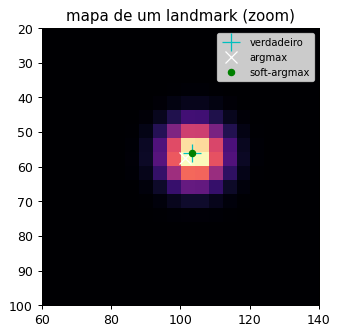

In [4]:
true_x, true_y = 103.4, 56.1
stride, size = 4, 64
ys, xs = np.mgrid[0:size, 0:size] * stride + (stride - 1) / 2       # centro de cada célula em pixels
sigma = 6.0
heat = np.exp(-((xs - true_x) ** 2 + (ys - true_y) ** 2) / (2 * sigma ** 2))
logit = torch.tensor(np.log(heat + 1e-12))[None, None]

j, i = np.unravel_index(heat.argmax(), heat.shape)
argmax_xy = (i * stride + (stride - 1) / 2, j * stride + (stride - 1) / 2)
soft_xy = soft_argmax(logit, stride)[0, 0].numpy()
print(f"verdadeiro: ({true_x:.1f}, {true_y:.1f})")
print(f"argmax:     ({argmax_xy[0]:.1f}, {argmax_xy[1]:.1f})   <- preso ao centro de uma célula")
print(f"soft-argmax:({soft_xy[0]:.1f}, {soft_xy[1]:.1f})   <- subpixel")

fig, ax = plt.subplots(figsize=(5, 4))
ax.imshow(heat[5:25, 15:35], extent=(15 * 4, 35 * 4, 25 * 4, 5 * 4), cmap="magma")
ax.plot(true_x, true_y, "c+", ms=14, label="verdadeiro")
ax.plot(*argmax_xy, "wx", ms=10, label="argmax")
ax.plot(*soft_xy, "g.", ms=10, label="soft-argmax")
ax.legend(fontsize=8); ax.set_title("mapa de um landmark (zoom)")
plt.show()

## 4. A função de perda

Treinamos com o erro absoluto (L1) entre a coordenada prevista e a anotada, dividido pelo
tamanho da entrada:

$$\mathcal{L} = \frac{1}{98}\sum_{k=1}^{98} w_k\,\frac{|\hat x_k - x_k| + |\hat y_k - y_k|}{256}$$

No baseline todos os pesos $w_k$ valem 1. No `06_olhos_fechados` vamos dar mais peso aos pontos dos olhos,
de 60 a 75.

### Por que não comparar direto os mapas com MSE? A armadilha dos mapas nulos

Se o alvo fosse um mapa com uma pequena mancha no lugar do ponto e a perda fosse o MSE pixel
a pixel, quase todo o mapa seria zero. A rede poderia então prever **tudo zero** e já ter uma
perda baixíssima, sem aprender nada. Como o soft-argmax calcula a perda **na coordenada**, essa
saída fácil não existe aqui.

In [5]:
target = np.exp(-((xs - true_x) ** 2 + (ys - true_y) ** 2) / (2 * 1.5 ** 2))     # alvo típico (σ pequeno)
mse_zero = ((0 - target) ** 2).mean()
mse_perfect_but_shifted = ((np.roll(target, 3, axis=1) - target) ** 2).mean()
print(f"MSE prevendo mapa todo ZERO:                  {mse_zero:.5f}")
print(f"MSE com o pico certo, deslocado 3 células:    {mse_perfect_but_shifted:.5f}")
print("-> o mapa nulo tem perda MENOR que um mapa útil deslocado: o MSE ensina a apagar o mapa.")

MSE prevendo mapa todo ZERO:                  0.00004
MSE com o pico certo, deslocado 3 células:    0.00008
-> o mapa nulo tem perda MENOR que um mapa útil deslocado: o MSE ensina a apagar o mapa.


In [6]:
def coordinate_loss(pred, target, input_size=256, weights=None):
    err = (pred - target).abs().sum(-1) / input_size          # (B, 98)
    if weights is not None:
        err = err * weights
    return err.mean()


# a perda de um modelo ainda não treinado: ele prevê ~o centro do recorte para todos os pontos
fake_target = torch.rand(2, 98, 2) * 256
print("coordenadas previstas (modelo novo), primeiras:", coords[0, :3].numpy().round(1))
print("perda L1 contra alvos aleatórios:", round(coordinate_loss(coords, fake_target).item(), 4))

coordenadas previstas (modelo novo), primeiras: [[127.5 127.5]
 [127.5 127.4]
 [127.5 127.5]]
perda L1 contra alvos aleatórios: 0.5229


A cabeça começa com pesos pequenos, então os mapas saem quase planos e o soft-argmax devolve
o **centro do recorte** (por volta de 127,5) para todos os pontos. É desse ponto que o treino
parte.

## 5. Um teste com uma face de verdade e o tempo na CPU

Pegamos um recorte do cache gerado no `02_preprocessamento` (os 256 pixels do centro) para
conferir que tudo funciona de ponta a ponta.

saída para 1 face: (1, 98, 2)


tempo por face na CPU (sem treino, só a rede): 73 ms


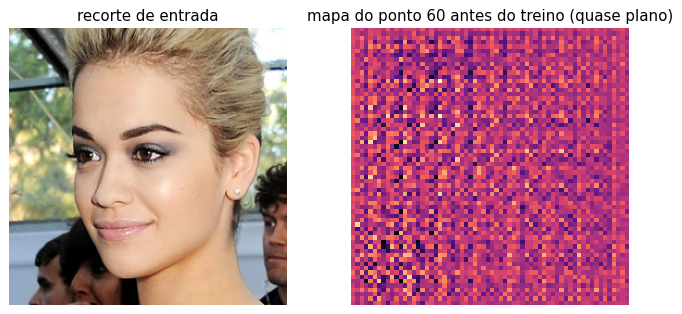

In [7]:
IMAGENET_MEAN = np.array([0.485, 0.456, 0.406], np.float32)
IMAGENET_STD = np.array([0.229, 0.224, 0.225], np.float32)


def to_tensor(image_rgb):
    # (H, W, 3) uint8 RGB -> (3, H, W) float normalizado como na ImageNet
    x = (image_rgb.astype(np.float32) / 255.0 - IMAGENET_MEAN) / IMAGENET_STD
    return torch.from_numpy(x.transpose(2, 0, 1).copy())


crops = np.load(PROCESSED / "train_crops.npy", mmap_mode="r")
face = np.asarray(crops[0])[64:320, 64:320]
model.eval()
with torch.no_grad():
    c, lg = model(to_tensor(face)[None])
print("saída para 1 face:", tuple(c.shape))

times = []
with torch.no_grad():
    for _ in range(10):
        t = time.perf_counter(); model(to_tensor(face)[None]); times.append(time.perf_counter() - t)
print(f"tempo por face na CPU (sem treino, só a rede): {1000 * np.median(times):.0f} ms")

fig, axes = plt.subplots(1, 2, figsize=(9, 4))
axes[0].imshow(face); axes[0].set_title("recorte de entrada"); axes[0].axis("off")
axes[1].imshow(F.softmax(lg[0, 60].flatten(), 0).reshape(64, 64).numpy(), cmap="magma")
axes[1].set_title("mapa do ponto 60 antes do treino (quase plano)"); axes[1].axis("off")
plt.show()

O tempo fica bem abaixo da meta de 2 segundos por imagem, o que deixa folga
para o detector de faces e para imagens com várias pessoas.

No próximo notebook, `04_treino.ipynb`, treinamos a rede.